# **Datos del alumno**


Sofia Jazmin Ruiz

Curso de Herramientas basicas para el analisis de datos

Fecha de entrega	11/11/2026


# 1 - Selección y alcance del dataset
##1.1 Descripción del dataset elegido

Nombre / fuente: UC Irvine Machine Learning Repository

Link de descarga: https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing


Formato: .csv


Diccionario de data set con unidades:

1	age:	Edad del cliente, en años.

2	job: Ocupación del cliente - técnico, estudiante, empleado administrativo, jubilado, etc.


3	marital: Estado civil - casado, soltero o divorciado. En este dataset, divorced también incluye a personas viudas.


4	education: Nivel educativo - primario, secundario, terciario o desconocido.

5	default: Indica si el cliente tiene incumplimientos crediticios registrados (yes o no).

6	balance: Saldo bancario promedio anual del cliente, expresado en euros.

7	housing: Indica si el cliente tiene un préstamo hipotecario (yes o no).

8	loan: Indica si tiene un préstamo personal (yes o no).


9	contact:	Medio de contacto utilizado -  teléfono fijo, celular o desconocido.


10	day: Día del mes en que se contactó al cliente por última vez durante la campaña actual.


11	month:	Mes del último contacto - enero, febrero, marzo, etc.

12	duration: Duración del último contacto, expresada en segundos.


13	campaign: Cantidad de contactos realizados al cliente durante la campaña actual, incluido el último.


14	pdays: 	Días transcurridos desde el contacto de una campaña anterior. El valor -1 indica que no había sido contactado previamente.


15	previous: Cantidad de contactos realizados antes de la campaña actual.

16	poutcome: Resultado de la campaña de marketing anterior - éxito, fracaso, otro o desconocido.

17	y:	Indica si el cliente contrató el depósito a plazo fijo ofrecido por el banco (yes o no).


- Cantidad de filas y columnas: 45211x17


##1.2 Preguntas de investigación
**Pregunta principal:** ¿Qué perfiles de clientes (ocupación, nivel educativo y edad) tienen mayor tasa de aceptación del depósito a plazo, y cómo se relacionan con su saldo?

**Subpregunta (KPI 1):** ¿Qué segmentos superan la tasa de aceptación global?


# 2 - Carga del dataset

In [1]:
#Importo librerias y conecto a Drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
from google.colab import drive
drive.mount('/content/drive')
RUTA_ARCHIVO="/content/drive/MyDrive/Curso UTN analisis de datos/bank-full.csv"

Mounted at /content/drive


In [2]:
data_cruda = pd.read_csv(
    RUTA_ARCHIVO,
    sep=";",
    encoding="utf-8"
)
print("Dimensiones:",data_cruda.shape) #Compruebo que el archivo tiene 45211 filas y 17 columnas
#Chequeo el inicio y el final del archivo, para constatar que no presenta irregularidades.
data_cruda.head(5)
data_cruda.tail(5)

Dimensiones: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


#3 - Preparacion de datos
##3.1 Diagnostico

In [3]:
#Formatos y tipos
data_cruda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


Hay 7 variables numéricas (int64) y 10 de texto (object). Los tipos numéricos son correctos. En cambio, las variables categóricas (job, marital, education, contact, poutcome, etc.) están como object y conviene pasarlas a category. La variable y contiene “yes”/”no” y conviene convertirla a booleano para facilitar el cálculo de tasas.

In [4]:
#Valores nulos
# Cantidad de nulos por columna
print(data_cruda.isna().sum())

# Total de nulos en todo el dataset
print("Total de nulos:", data_cruda.isna().sum().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Total de nulos: 0


isna() devuelve 0 en las 17 columnas, y info() muestra 45.211 valores no nulos en todas. No hay celdas vacías, por lo que no hace falta eliminar ni imputar registros. Sin embargo, esto no garantiza la calidad de los datos: algunas columnas categóricas usan la palabra “unknown” para representar datos faltantes, lo que se verifica en el siguiente paso de inconsistencias.

###Inconsistencias

In [5]:
#Filas duplicadas completas
print("Filas duplicadas:", data_cruda.duplicated().sum())

Filas duplicadas: 0


In [6]:
#Unknowns
columnas_texto = data_cruda.select_dtypes(include="object").columns

for col in columnas_texto:
    cantidad = (data_cruda[col] == "unknown").sum()
    if cantidad > 0:
        porcentaje = cantidad / len(data_cruda) * 100
        print(f"{col}: {cantidad} registros 'unknown' ({porcentaje:.1f}%)")

job: 288 registros 'unknown' (0.6%)
education: 1857 registros 'unknown' (4.1%)
contact: 13020 registros 'unknown' (28.8%)
poutcome: 36959 registros 'unknown' (81.7%)


In [7]:
#Inconsistencias en la escritura
columnas_texto = data_cruda.select_dtypes(include="object").columns

for col in columnas_texto:
    serie = data_cruda[col]
    con_espacios = (serie != serie.str.strip()).sum()
    con_mayusculas = (serie != serie.str.lower()).sum()
    print(f"{col}: {serie.nunique()} categorías | "
          f"espacios sobrantes: {con_espacios} | "
          f"con mayúsculas: {con_mayusculas}")

job: 12 categorías | espacios sobrantes: 0 | con mayúsculas: 0
marital: 3 categorías | espacios sobrantes: 0 | con mayúsculas: 0
education: 4 categorías | espacios sobrantes: 0 | con mayúsculas: 0
default: 2 categorías | espacios sobrantes: 0 | con mayúsculas: 0
housing: 2 categorías | espacios sobrantes: 0 | con mayúsculas: 0
loan: 2 categorías | espacios sobrantes: 0 | con mayúsculas: 0
contact: 3 categorías | espacios sobrantes: 0 | con mayúsculas: 0
month: 12 categorías | espacios sobrantes: 0 | con mayúsculas: 0
poutcome: 4 categorías | espacios sobrantes: 0 | con mayúsculas: 0
y: 2 categorías | espacios sobrantes: 0 | con mayúsculas: 0


In [8]:
for col in columnas_texto:
    print(f"\n{col}: {sorted(data_cruda[col].unique())}")


job: ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']

marital: ['divorced', 'married', 'single']

education: ['primary', 'secondary', 'tertiary', 'unknown']

default: ['no', 'yes']

housing: ['no', 'yes']

loan: ['no', 'yes']

contact: ['cellular', 'telephone', 'unknown']

month: ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']

poutcome: ['failure', 'other', 'success', 'unknown']

y: ['no', 'yes']


Se revisaron espacios sobrantes, mayúsculas/minúsculas y valores únicos en las 10 columnas de texto. No se detectaron inconsistencias de escritura: las categorías están escritas de forma uniforme, sin duplicados ni errores de tipeo. Las únicas inconsistencias halladas son los valores “unknown”

In [9]:
#Columnas sin utilidad
print(data_cruda.nunique().sort_values())

housing         2
loan            2
default         2
y               2
contact         3
marital         3
poutcome        4
education       4
month          12
job            12
day            31
previous       41
campaign       48
age            77
pdays         559
duration     1573
balance      7168
dtype: int64


Ninguna columna tiene un único valor (nunique() mínimo = 2) ni desviación estándar nula. No hay columnas con varianza nula que deban eliminarse por este criterio.

In [10]:
#Rangos anomalos
# 1) Estadisticos:
data_cruda.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


El resumen estadístico muestra que age (18 a 95 años) y day (1 a 31) tienen rangos válidos. balance presenta fuerte asimetría (media 1.362 contra mediana 448) y valores negativos, por lo que la mediana es una medida más representativa. pdays y previous están dominadas por un único valor (-1 y 0 respectivamente, que indican “sin contacto previo”) y duration y campaign muestran valores máximos muy alejados del percentil 75, lo que anticipa la presencia de outliers.

In [11]:
# 2) Regla del IQR para detectar outliers de forma objetiva

col = "age"

q1 = data_cruda[col].quantile(0.25)
q3 = data_cruda[col].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

outliers = data_cruda[(data_cruda[col] < limite_inf) | (data_cruda[col] > limite_sup)]
print(f"Rango esperado: [{limite_inf:.2f}, {limite_sup:.2f}]")
print(f"Outliers detectados: {len(outliers)} ({len(outliers)/len(data_cruda)*100:.1f}%)")
outliers.head()

col = "balance"

q1 = data_cruda[col].quantile(0.25)
q3 = data_cruda[col].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

outliers = data_cruda[(data_cruda[col] < limite_inf) | (data_cruda[col] > limite_sup)]
print(f"Rango esperado: [{limite_inf:.2f}, {limite_sup:.2f}]")
print(f"Outliers detectados: {len(outliers)} ({len(outliers)/len(data_cruda)*100:.1f}%)")
outliers.head()

Rango esperado: [10.50, 70.50]
Outliers detectados: 487 (1.1%)
Rango esperado: [-1962.00, 3462.00]
Outliers detectados: 4729 (10.5%)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
34,51,management,married,tertiary,no,10635,yes,no,unknown,5,may,336,1,-1,0,unknown,no
65,51,management,married,tertiary,no,6530,yes,no,unknown,5,may,91,1,-1,0,unknown,no
69,35,blue-collar,single,secondary,no,12223,yes,yes,unknown,5,may,177,1,-1,0,unknown,no
70,57,blue-collar,married,secondary,no,5935,yes,yes,unknown,5,may,258,1,-1,0,unknown,no
186,40,services,divorced,unknown,no,4384,yes,no,unknown,5,may,315,1,-1,0,unknown,no


Con la regla del IQR se detectaron 487 valores atípicos en age (1,1%), todos por encima de los 70 años, y 4.729 en balance (10,5%). Ninguno es un valor imposible: las edades son plausibles y los saldos negativos corresponden a descubiertos. Se decide conservarlos, porque representan clientes reales, y usar la mediana junto con la media al interpretar balance.Se aplica la regla del IQR a age y balance, que son las variables cuantitativas asociadas a las preguntas de investigación. El resto de las variables numéricas se revisó con describe().

Tabla de hallazgos del Diagnostico
| # | Dimensión | Problema detectado | Evidencia (método/salida) | Acción propuesta |
|---|-----------|--------------------|---------------------------|------------------|
| 1 | Nulos | No se detectaron valores nulos. | `isna().sum()` devuelve 0 en las 17 columnas; `info()` muestra 45.211 valores no nulos en todas. | Sin acción: no hay registros para eliminar ni imputar. |
| 2 | Formatos | Las variables categóricas están como `object` y `y` contiene "yes"/"no" como texto. | `info()`: 10 columnas `object` y 7 `int64`. | Convertir `job` y `education` a `category` y `y` a booleano (`acepto`), para calcular tasas de aceptación. |
| 3 | Inconsistencias | Hay "unknown" (dato faltante encubierto) en `job` (288, 0,6%), `education` (1.857, 4,1%), `contact` (13.020, 28,8%) y `poutcome` (36.959, 81,7%). La escritura es uniforme y no hay duplicados. | Conteo de "unknown" por columna; revisión de espacios, mayúsculas y valores únicos sin hallazgos; `duplicated().sum()` = 0. | Reemplazar "unknown" por `NaN` en `job` y `education` (variables de las preguntas) y excluirlos al analizarlas. `contact` y `poutcome` no se usan, así que no se modifican. |
| 4 | Varianza nula | No hay columnas con un único valor. | `nunique()` mínimo = 2; desviación estándar mayor que 0 en todas las numéricas. | Sin acción por este criterio. `pdays`, `previous`, `duration`, `contact` y `poutcome` quedan fuera por no ser relevantes para las preguntas, no por varianza nula. |
| 5 | Rangos anómalos | Hay valores atípicos en `age` (487, 1,1%) y `balance` (4.729, 10,5%). `balance` tiene fuerte asimetría y saldos negativos. | Regla del IQR: `age` fuera de [10,5 ; 70,5] y `balance` fuera de [-1.962 ; 3.462]; `describe()`: media de `balance` 1.362 contra mediana 448. | Conservarlos: son valores plausibles (clientes mayores de 70 años, saldos altos y descubiertos). Reportar la mediana junto con la media. |

## 3.2 Limpieza

In [12]:
# Copia del dataset original: acá se aplica toda la limpieza
data_set_limpio = data_cruda.copy()

# ID de 1 a 45211, como primera columna
data_set_limpio.insert(0, "id_cliente", range(1, len(data_set_limpio) + 1))

data_set_limpio.head()

,id_cliente,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [13]:
#Convierto los Unknown en NaN (a las columnas job y education)
data_set_limpio["job"] = data_set_limpio["job"].replace("unknown", np.nan)
data_set_limpio["education"] = data_set_limpio["education"].replace("unknown", np.nan)

# Verificación
print(data_set_limpio[["job", "education"]].isna().sum())

job           288
education    1857
dtype: int64


**Decisiones de no intervenir:**

- Filas con `NaN`: no se eliminan del dataset. Se excluyen solo al analizar la variable afectada, para no perder datos de más.
- `contact` y `poutcome`: contienen muchos "unknown", pero no se utilizan en las preguntas de investigación, por lo que no se modifican.
- Outliers de `age` y `balance`:se conservan, porque son valores plausibles que corresponden a clientes reales (personas mayores de 70 años, saldos altos y descubiertos).
- Duplicados y nulos: no se detectaron, por lo que no se requiere acción.

In [14]:
# Variables categóricas: de object a category
data_set_limpio["job"] = data_set_limpio["job"].astype("category")
data_set_limpio["education"] = data_set_limpio["education"].astype("category")

# Variable objetivo: de "yes"/"no" a booleano (True/False)
data_set_limpio["acepto"] = data_set_limpio["y"] == "yes"
data_set_limpio.info()
# Confirmo que acepto fue creada correctamente
print(data_set_limpio["acepto"].value_counts())
print(f"Tasa de aceptación global: {data_set_limpio['acepto'].mean() * 100:.1f}%")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   id_cliente  45211 non-null  int64   
 1   age         45211 non-null  int64   
 2   job         44923 non-null  category
 3   marital     45211 non-null  object  
 4   education   43354 non-null  category
 5   default     45211 non-null  object  
 6   balance     45211 non-null  int64   
 7   housing     45211 non-null  object  
 8   loan        45211 non-null  object  
 9   contact     45211 non-null  object  
 10  day         45211 non-null  int64   
 11  month       45211 non-null  object  
 12  duration    45211 non-null  int64   
 13  campaign    45211 non-null  int64   
 14  pdays       45211 non-null  int64   
 15  previous    45211 non-null  int64   
 16  poutcome    45211 non-null  object  
 17  y           45211 non-null  object  
 18  acepto      45211 non-null  bool    
dtypes: b

In [15]:
# Traduzo las diferentes categorias
traduccion_job = {
    "admin.": "administrativo",
    "blue-collar": "obrero",
    "entrepreneur": "emprendedor",
    "housemaid": "empleado doméstico",
    "management": "gerencia",
    "retired": "jubilado",
    "self-employed": "autónomo",
    "services": "servicios",
    "student": "estudiante",
    "technician": "técnico",
    "unemployed": "desempleado",
}

traduccion_educacion = {
    "primary": "primaria",
    "secondary": "secundaria",
    "tertiary": "terciaria",
}

data_set_limpio["job"] = data_set_limpio["job"].cat.rename_categories(traduccion_job)
data_set_limpio["education"] = data_set_limpio["education"].cat.rename_categories(traduccion_educacion)

print(data_set_limpio["job"].value_counts())
print(data_set_limpio["education"].value_counts())

job
obrero                9732
gerencia              9458
técnico               7597
administrativo        5171
servicios             4154
jubilado              2264
autónomo              1579
emprendedor           1487
desempleado           1303
empleado doméstico    1240
estudiante             938
Name: count, dtype: int64
education
secundaria    23202
terciaria     13301
primaria       6851
Name: count, dtype: int64


In [16]:
# Resultado final de la etapa: data_set_limpio
data_set_limpio = data_set_limpio.reset_index(drop=True).copy()

# Verificación automática — debe correr SIN errores
assert isinstance(data_set_limpio, pd.DataFrame), "data_set_limpio debe ser un DataFrame"
assert len(data_set_limpio) > 0, "El DataFrame quedó vacío: revisá tus filtros"
assert data_set_limpio.drop(columns="id_cliente").duplicated().sum() == 0, "Quedan filas duplicadas"

print("✅ data_set_limpio:", data_set_limpio.shape)
print(f"Filas eliminadas respecto del original: {len(data_cruda) - len(data_set_limpio)}")
data_set_limpio.head()

✅ data_set_limpio: (45211, 19)
Filas eliminadas respecto del original: 0


,id_cliente,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,acepto
0,1,58,gerencia,married,terciaria,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,False
1,2,44,técnico,single,secundaria,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,False
2,3,33,emprendedor,married,secundaria,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,False
3,4,47,obrero,married,NaN,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,False
4,5,33,NaN,single,NaN,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,False


#4 - Analisis de datos (EDA)
##4.1 Analisis univariado
### 4.1.1 Variables cualitativas

In [17]:
#job
frec_abs = data_set_limpio["job"].value_counts()
frec_rel = data_set_limpio["job"].value_counts(normalize=True)

tabla_frecuencias = pd.DataFrame({
    "frecuencia": frec_abs,
    "porcentaje": (frec_rel * 100).round(1),
})
print(tabla_frecuencias)
print("\nModa:", data_set_limpio["job"].mode()[0])

                    frecuencia  porcentaje
job                                       
obrero                    9732        21.7
gerencia                  9458        21.1
técnico                   7597        16.9
administrativo            5171        11.5
servicios                 4154         9.2
jubilado                  2264         5.0
autónomo                  1579         3.5
emprendedor               1487         3.3
desempleado               1303         2.9
empleado doméstico        1240         2.8
estudiante                 938         2.1

Moda: obrero


In [18]:
print("\nClientes contados en la tabla:", frec_abs.sum())
print("Registros NaN excluidos      :", data_set_limpio["job"].isna().sum())
print("Total del dataset            :", len(data_set_limpio))


Clientes contados en la tabla: 44923
Registros NaN excluidos      : 288
Total del dataset            : 45211


In [19]:
#education
frec_abs = data_set_limpio["education"].value_counts()
frec_rel = data_set_limpio["education"].value_counts(normalize=True)

tabla_frecuencias = pd.DataFrame({
    "frecuencia": frec_abs,
    "porcentaje": (frec_rel * 100).round(1),
})
print(tabla_frecuencias)
print("\nModa:", data_set_limpio["education"].mode()[0])

            frecuencia  porcentaje
education                         
secundaria       23202        53.5
terciaria        13301        30.7
primaria          6851        15.8

Moda: secundaria


In [20]:
print("\nClientes contados en la tabla:", frec_abs.sum())
print("Registros NaN excluidos      :", data_set_limpio["education"].isna().sum())
print("Total del dataset            :", len(data_set_limpio))


Clientes contados en la tabla: 43354
Registros NaN excluidos      : 1857
Total del dataset            : 45211


In [21]:
#acepto
frec_abs = data_set_limpio["acepto"].value_counts()
frec_rel = data_set_limpio["acepto"].value_counts(normalize=True)

tabla_frecuencias = pd.DataFrame({
    "frecuencia": frec_abs,
    "porcentaje": (frec_rel * 100).round(1),
})
print(tabla_frecuencias)
print("\nModa:", data_set_limpio["acepto"].mode()[0])

        frecuencia  porcentaje
acepto                        
False        39922        88.3
True          5289        11.7

Moda: False


**`job`:** la ocupación más frecuente es obrero (21,7%), seguida de cerca por gerencia (21,1%). estudiante es la menos frecuente (2,1%). Los porcentajes excluyen los 288 registros con ocupación desconocida.

**`education`:** el nivel educativo más frecuente es `secundaria` (23.202 clientes, 53,5%), seguido de `terciaria` (30,7%) y `primaria` (15,8%). Más de la mitad de los clientes tiene educación secundaria. Los porcentajes excluyen los 1.857 registros con nivel educativo desconocido.

**`acepto`:** la moda es `False`: el 88,3% de los clientes (39.922) no aceptó la oferta y solo el 11,7% (5.289) la aceptó. La variable está desbalanceada, por lo que al comparar grupos conviene usar tasas (porcentajes dentro de cada grupo) y no cantidades absolutas.

### 4.1.2 Variables cuantitativas

In [22]:
#age
variable_age = data_set_limpio["age"]

print("Media    :", round(variable_age.mean(), 2))
print("Mediana  :", round(variable_age.median(), 2))
print("Desvío   :", round(variable_age.std(), 2))
print("Mínimo   :", variable_age.min())
print("Máximo   :", variable_age.max())
print("IQR      :", round(variable_age.quantile(0.75) - variable_age.quantile(0.25), 2))
print("Asimetría:", round(variable_age.skew(), 2))

Media    : 40.94
Mediana  : 39.0
Desvío   : 10.62
Mínimo   : 18
Máximo   : 95
IQR      : 15.0
Asimetría: 0.68


**`age`:** la edad media es de 40,9 años y la mediana de 39, valores muy cercanos, con un desvío de 10,6 años. El 50% central de los clientes tiene entre 33 y 48 años (IQR = 15). La media representa bien al cliente típico.

In [23]:
#balance
variable_balance = data_set_limpio["balance"]

print("Media    :", round(variable_balance.mean(), 2))
print("Mediana  :", round(variable_balance.median(), 2))
print("Desvío   :", round(variable_balance.std(), 2))
print("Mínimo   :", variable_balance.min())
print("Máximo   :", variable_balance.max())
print("IQR      :", round(variable_balance.quantile(0.75) - variable_balance.quantile(0.25), 2))
print("Asimetría:", round(variable_balance.skew(), 2))

Media    : 1362.27
Mediana  : 448.0
Desvío   : 3044.77
Mínimo   : -8019
Máximo   : 102127
IQR      : 1356.0
Asimetría: 8.36


**`balance`:** el saldo en euros medio es de 1.362 y la mediana de 448, con un desvío de 3.045. La media triplica a la mediana y la asimetría es muy alta (8,36): unos pocos clientes con saldos muy elevados (máximo 102.127) tiran la media hacia arriba. La mediana describe mejor al cliente típico. El IQR es de 1.356, y el mínimo (-8.019) corresponde a clientes con descubierto.

##4.2 Analisis bivariado

### Tasa de aceptacion por ocupacion.

In [24]:
resumen_job = (
    data_set_limpio.groupby("job", observed=True)["acepto"]
    .agg(clientes="count", aceptaron="sum", tasa_pct="mean")
)
resumen_job["tasa_pct"] = (resumen_job["tasa_pct"] * 100).round(1)

print(f"Tasa de aceptación global: {data_set_limpio['acepto'].mean() * 100:.1f}%\n")
print(resumen_job.sort_values("tasa_pct", ascending=False))

Tasa de aceptación global: 11.7%

                    clientes  aceptaron  tasa_pct
job                                              
estudiante               938        269      28.7
jubilado                2264        516      22.8
desempleado             1303        202      15.5
gerencia                9458       1301      13.8
administrativo          5171        631      12.2
autónomo                1579        187      11.8
técnico                 7597        840      11.1
servicios               4154        369       8.9
empleado doméstico      1240        109       8.8
emprendedor             1487        123       8.3
obrero                  9732        708       7.3


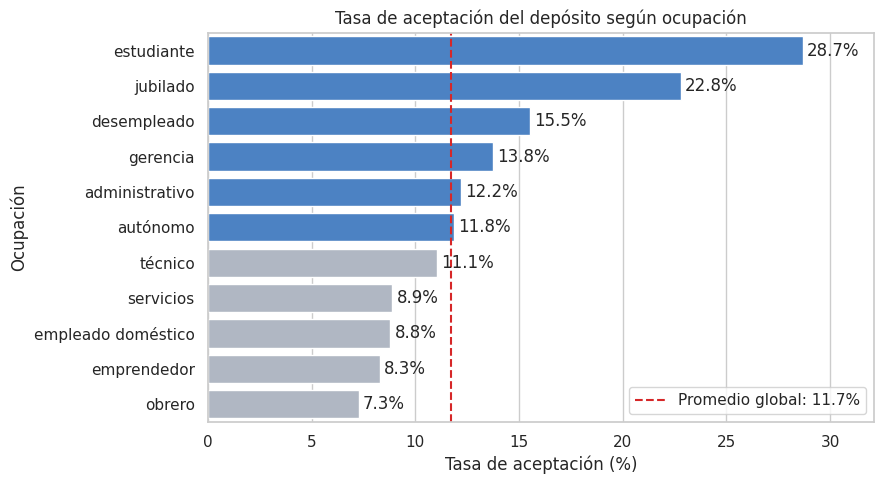

In [25]:
# Grafico
tasa_global = data_set_limpio["acepto"].mean() * 100

tasa_job = (
    data_set_limpio.groupby("job", observed=True)["acepto"].mean() * 100
).sort_values(ascending=False).reset_index(name="tasa")

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=tasa_job, x="tasa", y="job", order=tasa_job["job"].tolist(), color="#4C82C3")

# Azul si supera el promedio global, gris si no
for barra, valor in zip(ax.patches, tasa_job["tasa"]):
    barra.set_facecolor("#4C82C3" if valor > tasa_global else "#B0B7C3")

plt.axvline(tasa_global, color="#D62728", linestyle="--", label=f"Promedio global: {tasa_global:.1f}%")
plt.title("Tasa de aceptación del depósito según ocupación")
plt.xlabel("Tasa de aceptación (%)")
plt.ylabel("Ocupación")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.xlim(0, tasa_job["tasa"].max() * 1.12)
plt.legend()
plt.tight_layout()
plt.show()

**Gráfico 1:** seis de las once ocupaciones superan la tasa de aceptación global (11,7%). Se destacan `estudiante` (28,7%) y `jubilado` (22,8%), con más del doble del promedio, mientras que `obrero` (7,3%) es la más baja. Se compara por tasa y no por cantidad, porque grupos grandes como `gerencia` suman más aceptaciones absolutas pero con una tasa menor.

### Tasa de aceptación por nivel educativo

In [26]:
resumen_edu = (
    data_set_limpio.groupby("education", observed=True)["acepto"]
    .agg(clientes="count", aceptaron="sum", tasa_pct="mean")
)
resumen_edu["tasa_pct"] = (resumen_edu["tasa_pct"] * 100).round(1)

print(resumen_edu.sort_values("tasa_pct", ascending=False))

            clientes  aceptaron  tasa_pct
education                                
terciaria      13301       1996      15.0
secundaria     23202       2450      10.6
primaria        6851        591       8.6


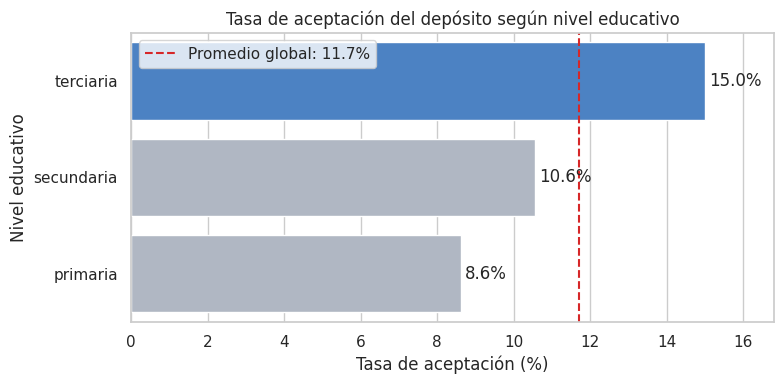

In [27]:
#Grafico
tasa_global = data_set_limpio["acepto"].mean() * 100

tasa_edu = (
    data_set_limpio.groupby("education", observed=True)["acepto"].mean() * 100
).sort_values(ascending=False).reset_index(name="tasa")

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=tasa_edu, x="tasa", y="education", order=tasa_edu["education"].tolist(), color="#4C82C3")

# Azul si supera el promedio global, gris si no
for barra, valor in zip(ax.patches, tasa_edu["tasa"]):
    barra.set_facecolor("#4C82C3" if valor > tasa_global else "#B0B7C3")

plt.axvline(tasa_global, color="#D62728", linestyle="--", label=f"Promedio global: {tasa_global:.1f}%")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.xlim(0, tasa_edu["tasa"].max() * 1.12)
plt.title("Tasa de aceptación del depósito según nivel educativo")
plt.xlabel("Tasa de aceptación (%)")
plt.ylabel("Nivel educativo")
plt.legend()
plt.tight_layout()
plt.show()

**Gráfico 2:** la tasa de aceptación crece con el nivel educativo: 8,6% en `primaria`, 10,6% en `secundaria` y 15,0% en `terciaria`. Solo el nivel terciario supera la tasa global (11,7%). Es el segmento con mayor propensión a aceptar entre los tres niveles, aunque la diferencia es moderada comparada con la que se vio por ocupación. Se excluyen los clientes con nivel educativo desconocido. Una breve aclaracion: si bien secundaria concentra más aceptaciones absolutas (2.450) que terciaria (1.996), su tasa es menor.

### Tasa de aceptación por tramo de edad

In [28]:
tramo_edad = pd.cut(
    data_set_limpio["age"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"],
).rename("tramo_edad")

resumen_edad = (
    data_set_limpio.groupby(tramo_edad, observed=True)["acepto"]
    .agg(clientes="count", aceptaron="sum", tasa_pct="mean")
)
resumen_edad["tasa_pct"] = (resumen_edad["tasa_pct"] * 100).round(1)

print(resumen_edad)

            clientes  aceptaron  tasa_pct
tramo_edad                               
18-25           1336        320      24.0
26-35          15571       1869      12.0
36-45          13856       1301       9.4
46-55           9548        893       9.4
56-65           4149        586      14.1
66+              751        320      42.6


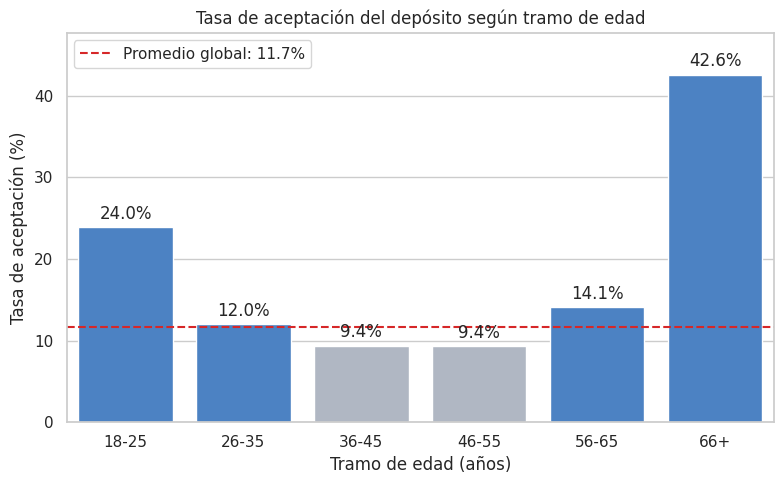

In [29]:
# Grafico
tasa_global = data_set_limpio["acepto"].mean() * 100

tasa_edad = (
    data_set_limpio.groupby(tramo_edad, observed=True)["acepto"].mean() * 100
).reset_index(name="tasa")

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=tasa_edad, x="tramo_edad", y="tasa",
                 order=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"], color="#4C82C3")

# Azul si supera el promedio global, gris si no
for barra, valor in zip(ax.patches, tasa_edad["tasa"]):
    barra.set_facecolor("#4C82C3" if valor > tasa_global else "#B0B7C3")

plt.axhline(tasa_global, color="#D62728", linestyle="--", label=f"Promedio global: {tasa_global:.1f}%")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.ylim(0, tasa_edad["tasa"].max() * 1.12)
plt.title("Tasa de aceptación del depósito según tramo de edad")
plt.xlabel("Tramo de edad (años)")
plt.ylabel("Tasa de aceptación (%)")
plt.legend()
plt.tight_layout()
plt.show()

**Gráfico 3:** la tasa de aceptación no crece de forma lineal con la edad, sino que forma una U: es más alta en los extremos, con 24,0% en el tramo 18-25 y 42,6% en el de 66 años o más, y más baja en los tramos intermedios (9,4% entre 36 y 55 años). Los clientes de mayor edad aceptan casi cuatro veces más que el promedio global (11,7%). El tramo 66+ tiene solo 751 clientes, por lo que su tasa es menos estable que la de los demás.

**Hasta acá:** la aceptación varía según ocupación, educación y edad. Como los clientes de mayor edad también tienden a tener más saldo, surge una pregunta: ¿los clientes que aceptan el depósito tienen un saldo distinto de los que no? El gráfico 4 compara el saldo según la decisión del cliente.

### Saldo según aceptación

In [30]:
resumen_saldo = (
    data_set_limpio.groupby("acepto")["balance"]
    .agg(clientes="count", media="mean", mediana="median")
    .round(1)
)
resumen_saldo.index = ["No aceptó", "Aceptó"]
print(resumen_saldo)

           clientes   media  mediana
No aceptó     39922  1303.7    417.0
Aceptó         5289  1804.3    733.0


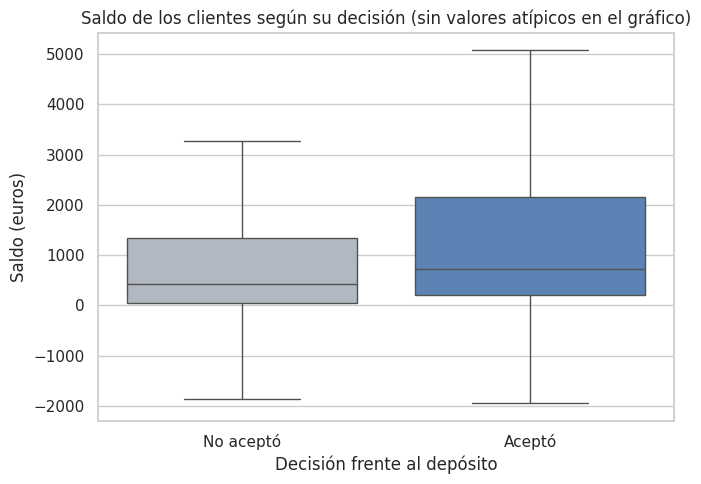

In [31]:
# Grafico
etiquetas = data_set_limpio["acepto"].map({False: "No aceptó", True: "Aceptó"})

plt.figure(figsize=(7, 5))
sns.boxplot(x=etiquetas, y=data_set_limpio["balance"], order=["No aceptó", "Aceptó"],
            showfliers=False, palette=["#B0B7C3", "#4C82C3"], hue=etiquetas, legend=False)
plt.title("Saldo de los clientes según su decisión (sin valores atípicos en el gráfico)")
plt.xlabel("Decisión frente al depósito")
plt.ylabel("Saldo (euros)")
plt.tight_layout()
plt.show()

**Gráfico 4:** los clientes que aceptaron el depósito tienen un saldo mediano de 733 euros, frente a 417 euros de quienes no aceptaron, es decir, casi el doble. La media muestra la misma tendencia (1.804 contra 1.304 euros). Sin embargo, las cajas se solapan en buena parte, por lo que el saldo ayuda a distinguir perfiles pero no los separa con claridad. Los valores atípicos se ocultan en el gráfico para poder leerlo, pero se incluyen en la tabla.

#5 - KPI


In [32]:
kpi_tasa = data_set_limpio["acepto"].mean() * 100
kpi_aceptaron = int(data_set_limpio["acepto"].sum())
kpi_saldo_mediano = data_set_limpio["balance"].median()

print(f"KPI 1 - Tasa de aceptación global : {kpi_tasa:.1f}%")
print(f"KPI 2 - Clientes que aceptaron    : {kpi_aceptaron:,}".replace(",", "."))
print(f"KPI 3 - Saldo mediano             : {kpi_saldo_mediano:,.0f} euros".replace(",", "."))

KPI 1 - Tasa de aceptación global : 11.7%
KPI 2 - Clientes que aceptaron    : 5.289
KPI 3 - Saldo mediano             : 448 euros


### KPIs

| KPI | Definición | Cálculo |
|---|---|---|
| Tasa de aceptación global | Porcentaje de clientes que contrataron el depósito a plazo | `acepto.mean() * 100` |
| Clientes que aceptaron | Cantidad de clientes que contrataron el depósito | `acepto.sum()` |
| Saldo mediano (euros) | Saldo anual típico del cliente, robusto a valores extremos | `balance.median()` |

Se usa la mediana y no la media del saldo porque la distribución es muy asimétrica (unos pocos saldos muy altos distorsionan el promedio).

### Subpregunta: ¿Que segmentos superan la tasa global?

In [33]:
def tasa_por(agrupador, dimension):
    t = data_set_limpio.groupby(agrupador, observed=True)["acepto"].agg(clientes="count", tasa_pct="mean")
    t["tasa_pct"] = (t["tasa_pct"] * 100).round(1)
    t.index = t.index.astype(str)
    t.index.name = "segmento"
    t.insert(0, "dimension", dimension)
    return t.reset_index()

segmentos = pd.concat([
    tasa_por("job", "Ocupación"),
    tasa_por("education", "Nivel educativo"),
    tasa_por(tramo_edad, "Edad"),
], ignore_index=True)

segmentos_sobre_global = (
    segmentos[segmentos["tasa_pct"] > kpi_tasa]
    .sort_values("tasa_pct", ascending=False)
    .reset_index(drop=True)
)
print(f"Segmentos que superan la tasa global ({kpi_tasa:.1f}%): {len(segmentos_sobre_global)}\n")
print(segmentos_sobre_global)

Segmentos que superan la tasa global (11.7%): 11

          segmento        dimension  clientes  tasa_pct
0              66+             Edad       751      42.6
1       estudiante        Ocupación       938      28.7
2            18-25             Edad      1336      24.0
3         jubilado        Ocupación      2264      22.8
4      desempleado        Ocupación      1303      15.5
5        terciaria  Nivel educativo     13301      15.0
6            56-65             Edad      4149      14.1
7         gerencia        Ocupación      9458      13.8
8   administrativo        Ocupación      5171      12.2
9            26-35             Edad     15571      12.0
10        autónomo        Ocupación      1579      11.8


**KPI 1 (subpregunta):** 11 segmentos superan la tasa de aceptación global (11,7%). Los de mayor tasa son los clientes de 66 años o más (42,6%), los estudiantes (28,7%), los de 18 a 25 años (24,0%) y los jubilados (22,8%). Son grupos relativamente chicos, por lo que conviene leerlos junto con su cantidad de clientes: segmentos grandes como `gerencia` (9.458 clientes) o el tramo 26-35 (15.571) superan el promedio por muy poco.

## Conclusiones

**Pregunta principal:** ¿qué perfiles de clientes tienen mayor tasa de aceptación del depósito y cómo se relacionan con su saldo?

- **Ocupación:** estudiantes (28,7%) y jubilados (22,8%) aceptan más del doble que el promedio global (11,7%); los obreros son los de menor tasa (7,3%).
- **Educación:** la tasa crece con el nivel educativo, de 8,6% en primaria a 15,0% en terciaria.
- **Edad:** la relación tiene forma de U: aceptan más los clientes de 66 años o más (42,6%) y los de 18 a 25 (24,0%), y menos los de 36 a 55 (9,4%).
- **Saldo:** quienes aceptaron tienen un saldo mediano de 733 euros, frente a 417 euros de quienes no aceptaron. Las distribuciones se solapan bastante, por lo que el saldo ayuda a describir perfiles pero no los separa con claridad.

**Subpregunta**: ¿Qué segmentos superan la tasa de aceptación global?
 11 segmentos superan la tasa global de 11,7%, entre ellos clientes de 66 años o más, estudiantes, jóvenes de 18 a 25 años y jubilados.

**Limitaciones:** los resultados muestran asociaciones, no causas. Los segmentos con tasas más altas son relativamente chicos (por ejemplo, 751 clientes de 66 años o más), por lo que son menos estables. Se excluyeron del análisis los registros con ocupación o educación desconocida (4,5% del total).

## Exportación para Power BI

Se genera `bank_marketing_powerbi.csv` con las columnas necesarias para el dashboard: identificador, edad y tramo de edad, ocupación, nivel educativo, saldo en euros y la decisión del cliente (`acepto` como 1/0 para calcular la tasa de aceptación como promedio). Los registros con ocupación o educación desconocida se mantienen vacíos, igual que en el análisis en Python.

In [34]:
df_powerbi = pd.DataFrame({
    "id_cliente": data_set_limpio["id_cliente"],
    "edad": data_set_limpio["age"],
    "tramo_edad": tramo_edad.astype(str),
    "ocupacion": data_set_limpio["job"].astype(object),
    "educacion": data_set_limpio["education"].astype(object),
    "saldo_euros": data_set_limpio["balance"],
    "acepto": data_set_limpio["acepto"].astype(int),
    "decision": data_set_limpio["acepto"].map({True: "Aceptó", False: "No aceptó"}),
})

print("Dimensiones:", df_powerbi.shape)
print("\nNulos por columna:")
print(df_powerbi.isna().sum())
print(f"\nTasa de aceptación: {df_powerbi['acepto'].mean() * 100:.1f}%")
df_powerbi.head()

Dimensiones: (45211, 8)

Nulos por columna:
id_cliente        0
edad              0
tramo_edad        0
ocupacion       288
educacion      1857
saldo_euros       0
acepto            0
decision          0
dtype: int64

Tasa de aceptación: 11.7%


,id_cliente,edad,tramo_edad,ocupacion,educacion,saldo_euros,acepto,decision
0,1,58,56-65,gerencia,terciaria,2143,0,No aceptó
1,2,44,36-45,técnico,secundaria,29,0,No aceptó
2,3,33,26-35,emprendedor,secundaria,2,0,No aceptó
3,4,47,46-55,obrero,NaN,1506,0,No aceptó
4,5,33,26-35,NaN,NaN,1,0,No aceptó


In [35]:
df_powerbi.to_csv("bank_marketing_powerbi.csv", index=False, encoding="utf-8-sig")

from google.colab import files
files.download("bank_marketing_powerbi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>